In [3]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 83.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.9 MB/s eta 0:00:00


In [4]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [5]:
import zipfile

In [10]:
zipfile.ZipFile('/content/license_plate.v5i.yolov11.zip').extractall()

In [11]:
model.train(data='/content/license plate.v5i.yolov11/data.yaml',epochs=20)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/license plate.v5i.yolov11/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7cd0b9f07cf0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [12]:
metrics = model.val(
    data="/content/license plate.v5i.yolov11/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 674.7±250.0 MB/s, size: 27.2 KB)
val: Scanning /content/license plate.v5i.yolov11/test/labels... 62 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 62/62 827.9it/s 0.1s
val: New cache created: /content/license plate.v5i.yolov11/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5it/s 2.7s
                   all         62         62      0.999          1      0.995      0.726
Speed: 7.2ms preprocess, 14.5ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to /content/runs/detect/val
mAP50: 0.995
mAP50-95: 0.7264298462462666
Precision: 0.9986037624692181
Recall: 1.0


In [19]:
pred = model.predict('/content/gettyimages-807748644-640x640.jpg')


image 1/1 /content/gettyimages-807748644-640x640.jpg: 384x640 3 license plates, 8.9ms
Speed: 1.4ms preprocess, 8.9ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)


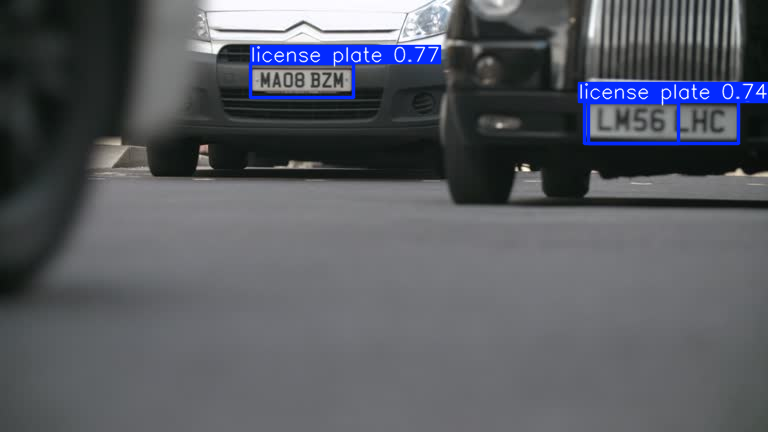

In [20]:
pred[0].show()

In [21]:
Mymodel = YOLO("/content/runs/detect/train/weights/best.pt")


image 1/1 /content/gettyimages-807748644-640x640.jpg: 384x640 3 license plates, 12.8ms
Speed: 2.0ms preprocess, 12.8ms inference, 1.8ms postprocess per image at shape (1, 3, 384, 640)


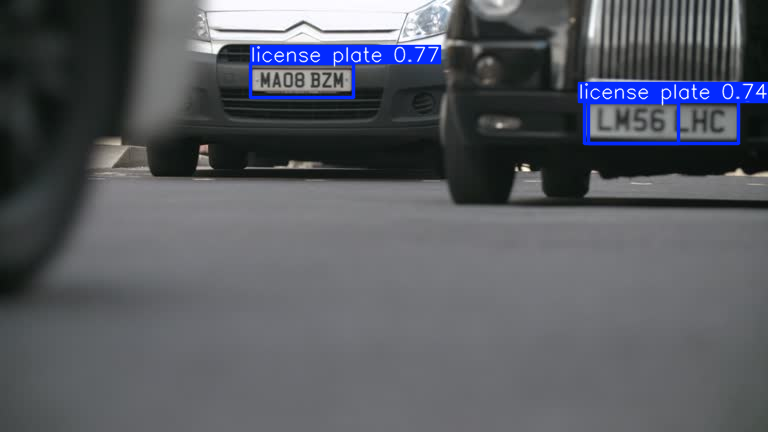

In [23]:
Mymodel.predict('/content/gettyimages-807748644-640x640.jpg')[0].show()

In [24]:
from google.colab import files

# Apni file ka sahi path yahan dein (misal ke tor par YOLOv11 ka weights path)
files.download('/content/runs/detect/train/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>